# Coding SVs against every other SV

The burden model splits SVs by genomic context, and those context burdens correlate **0.86–0.96** across
founders. Two questions follow, and this notebook answers both with fits rather than argument.

**1. Are we missing SVs?** We were. The reported model carries terms for CDS, reference TE, promoter and
intergenic — so **UTR and intron variants entered no burden at all**: 3,685 of 18,418 passing events
(**20 %**), and 24 % of the events a typical founder carries. §2 adds every context as its own term and
asks whether that omission mattered.

**2. Do non-coding SVs really associate positively with fitness?** In the four-context model, CDS comes out
negative and the other three positive — which is hard to credit when the predictors correlate at 0.9. §3
collapses the model to **two** burdens, coding and everything-else, so the contrast is estimated directly
instead of being read off four collinear coefficients.

## The models

Both are the main model with only the burden terms changed. Every covariate is retained: the matched SNP
coding burden, assembly route, founder origin climate **and its interaction with garden climate**, SNP
kinship, a garden intercept, random garden slopes, and local adaptation fitted **per garden**.

```r
# all6 -- every genomic context its own term (closes the UTR/intron gap)
y ~ snp_CDS + sv_CDS + sv_UTR + sv_intron + sv_TE + sv_promoter + sv_intergenic + cactus
    + sv_CDS:bio1c + sv_TE:bio1c + sv_promoter:bio1c
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_CDS | garden) + (0 + sv_TE | garden) + (0 + sv_promoter | garden)

# cds2 -- coding against everything else
y ~ snp_CDS + sv_CDS + sv_nonCDS + cactus
    + sv_CDS:bio1c + sv_nonCDS:bio1c
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_CDS | garden) + (0 + sv_nonCDS | garden)
```

`sv_nonCDS` pools UTR + intron + TE + promoter + intergenic into one carried/called rate, so **every
passing SV event is now in exactly one burden**.

⚠ The two predictors still correlate **r = 0.887** — collapsing to two terms does not remove the
collinearity, it makes what is being contrasted explicit.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
CT6=["CDS","UTR","intron","TE","promoter","intergenic"]
CC={"CDS":"#4A3B6B","nonCDS":"#C46A10","UTR":"#6B5A8E","intron":"#7E9B6B","TE":"#6B5A8E",
    "promoter":"#9084AE","intergenic":"#C6BCD8","snp_CDS":"0.25"}
def arm(tag):
    S=f"_x_obio1cobio1cbio1c_re0obio1cgarden{tag}_refid"   # THE model: LA fitted per garden
    o={"co":pd.read_csv(f"{PA}/coef_M2p_reml{S}.csv").set_index("term"),
       "sc":pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c{tag}.csv").set_index("context"),
       "V":pd.read_csv(f"{PA}/vcov_M2p_reml{S}.csv",index_col=0),
       "vc":pd.read_csv(f"{PA}/varcomp_M2p_reml{S}.csv"),
       "gd":pd.read_csv(f"{PA}/garden_M2p_reml{S}.csv"),
       "ll":pd.read_csv(f"{PA}/loglik_M2p_reml{S}.csv").iloc[0],"suf":S}
    o["pv"]={f"sv_{c}":100/(o["sc"].loc[c,"sd_rate"]*o["sc"].loc[c,"med_called"]) for c in o["sc"].index}
    return o
M2,M6,MAIN=arm("_cds2"),arm("_all6"),arm("")
# the burden x garden-temperature interactions, judged by likelihood-ratio test: ML refits with and
# without that single interaction, 1 df. Reported uncorrected.
def lrts(o,terms):
    ll=lambda n: pd.read_csv(f"{PA}/loglik_{n}{o['suf']}.csv").logLik[0]
    return {t: stats.chi2.sf(2*(ll("M2p_ml")-ll(f"M2p_ml_drop_{t}")),1) for t in terms}
M2["LRT"]=lrts(M2,["sv_CDS","sv_nonCDS"])
M6["LRT"]=lrts(M6,["sv_CDS","sv_TE","sv_promoter"])
CAT=pd.read_csv(f"{G}/sv_event_catalog.csv"); AP=CAT[CAT.passes]
B=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str})
car={c:B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"] for c in CT6}
cal={c:B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"] for c in CT6}
IN4={"CDS","TE","promoter","intergenic"}
print("SV events by genomic context, and where each went before these fits:\n")
print(pd.DataFrame([{"context":c,"events":int((AP.context==c).sum()),
                     "median carried per founder":int(car[c].median()),
                     "in the 4-context model":"yes" if c in IN4 else "NO -- entered nothing"}
                    for c in CT6]).to_string(index=False))
mis=int(AP.context.isin({"UTR","intron"}).sum())
print(f"\n  omitted: {mis:,} of {len(AP):,} events = {100*mis/len(AP):.1f}%; "
      f"{int((car['UTR']+car['intron']).median()):,} of {int(sum(car[c] for c in CT6).median()):,} "
      f"carried per founder = {100*(car['UTR']+car['intron']).median()/sum(car[c] for c in CT6).median():.0f}%")
rc=car["CDS"]/cal["CDS"]; rn=sum(car[c] for c in CT6 if c!="CDS")/sum(cal[c] for c in CT6 if c!="CDS")
print(f"\n  correlation of the coding burden with the non-coding burden across founders: "
      f"r = {np.corrcoef(rc,rn)[0,1]:+.3f}")
for nm,o in (("cds2",M2),("all6",M6)):
    print(f"  {nm:<6} logLik {o['ll'].logLik:.4f}  df {int(o['ll'].df)}  singular {o['ll'].singular}")


SV events by genomic context, and where each went before these fits:

   context  events  median carried per founder in the 4-context model
       CDS    1407                         149                    yes
       UTR    1234                         136  NO -- entered nothing
    intron    2451                         332  NO -- entered nothing
        TE    2968                         426                    yes
  promoter    7138                         626                    yes
intergenic    3220                         299                    yes

  omitted: 3,685 of 18,418 events = 20.0%; 470 of 1,972 carried per founder = 24%

  correlation of the coding burden with the non-coding burden across founders: r = +0.887
  cds2   logLik -11083.4962  df 15  singular False
  all6   logLik -11095.9896  df 21  singular False


## 1 · Are we missing SVs? — every context as its own term

`all6` gives UTR and intron their own burden terms, so every passing SV event enters exactly one burden.
The question is whether the 20 % that had been excluded was carrying signal, and whether excluding it had
distorted the coding estimate.

Open markers are terms that were already in the model; **filled orange** marks the two that had been
missing entirely.

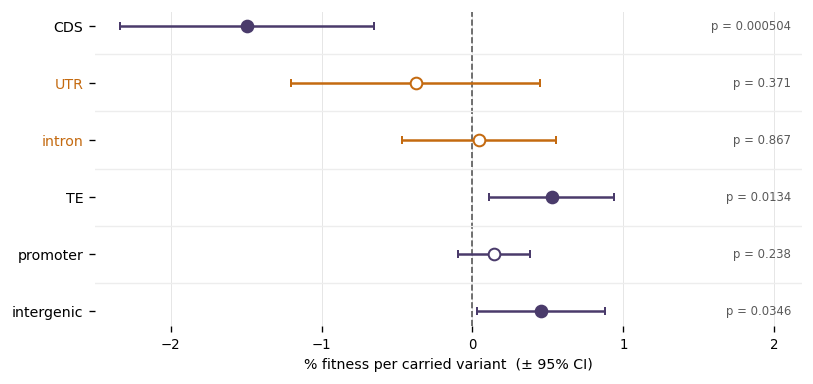

EVERY CONTEXT AS ITS OWN TERM:

   context %/carried variant           95% CI    Wald p was in the model
       CDS           -1.4944 [-2.336, -0.652] 0.0005042              yes
       UTR           -0.3765 [-1.201, +0.448]     0.371               NO
    intron           +0.0434 [-0.465, +0.552]    0.8671               NO
        TE           +0.5238 [+0.109, +0.939]   0.01339              yes
  promoter           +0.1441 [-0.095, +0.383]    0.2377              yes
intergenic           +0.4550 [+0.033, +0.877]    0.0346              yes

Did the omission distort the coding estimate?
  sv_CDS with UTR+intron excluded : -1.4949% (p = 0.0004842)
  sv_CDS with every context in    : -1.4944% (p = 0.0005042)
  difference +0.00052 percentage points (0.001 SE)

  UTR and intron are individually null, and putting them in leaves the coding estimate untouched:
  the gap was real but harmless.


In [3]:

ORD=["CDS","UTR","intron","TE","promoter","intergenic"]; NEW={"UTR","intron"}
fig,a=plt.subplots(figsize=(7.6,3.4)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
for i,c in enumerate(ORD):
    t=f"sv_{c}"; e,se=M6["co"].loc[t,"estimate"]*M6["pv"][t], M6["co"].loc[t,"se"]*M6["pv"][t]
    col="#C46A10" if c in NEW else "#4A3B6B"
    a.errorbar(e,i,xerr=1.96*se,fmt="o",color=col,mfc=col if M6["co"].loc[t,"p"]<0.05 else "white",
               mew=1.2,ms=7,capsize=2.5,zorder=3)
    a.annotate(f"p = {M6['co'].loc[t,'p']:.3g}",xy=(0.985,i),xycoords=("axes fraction","data"),
               ha="right",va="center",fontsize=7,color="0.35")
    if i<len(ORD)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(ORD)))
a.set_yticklabels(ORD,fontsize=8.5)
for lb,c in zip(a.get_yticklabels(),ORD):
    if c in NEW: lb.set_color("#C46A10")
a.invert_yaxis(); x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.30*(x1-x0))
a.set_xlabel("% fitness per carried variant  (± 95% CI)",fontsize=8.5)
save(fig,"cdsrest_all6",nb=True); plt.show()
print("EVERY CONTEXT AS ITS OWN TERM:\n")
print(pd.DataFrame([{"context":c,"%/carried variant":f"{M6['co'].loc['sv_'+c,'estimate']*M6['pv']['sv_'+c]:+.4f}",
  "95% CI":f"[{(M6['co'].loc['sv_'+c,'estimate']-1.96*M6['co'].loc['sv_'+c,'se'])*M6['pv']['sv_'+c]:+.3f}, "
           f"{(M6['co'].loc['sv_'+c,'estimate']+1.96*M6['co'].loc['sv_'+c,'se'])*M6['pv']['sv_'+c]:+.3f}]",
  "Wald p":f"{M6['co'].loc['sv_'+c,'p']:.4g}",
  "was in the model":"yes" if c in IN4 else "NO"} for c in ORD]).to_string(index=False))
d=M6["co"].loc["sv_CDS","estimate"]*M6["pv"]["sv_CDS"]-MAIN["co"].loc["sv_CDS","estimate"]*MAIN["pv"]["sv_CDS"]
print(f"\nDid the omission distort the coding estimate?")
print(f"  sv_CDS with UTR+intron excluded : {MAIN['co'].loc['sv_CDS','estimate']*MAIN['pv']['sv_CDS']:+.4f}% "
      f"(p = {MAIN['co'].loc['sv_CDS','p']:.4g})")
print(f"  sv_CDS with every context in    : {M6['co'].loc['sv_CDS','estimate']*M6['pv']['sv_CDS']:+.4f}% "
      f"(p = {M6['co'].loc['sv_CDS','p']:.4g})")
print(f"  difference {d:+.5f} percentage points "
      f"({abs(M6['co'].loc['sv_CDS','estimate']-MAIN['co'].loc['sv_CDS','estimate'])/MAIN['co'].loc['sv_CDS','se']:.3f} SE)")
print("\n  UTR and intron are individually null, and putting them in leaves the coding estimate untouched:")
print("  the gap was real but harmless.")


## 2 · Coding against everything else

Two burdens only — `sv_CDS` and `sv_nonCDS`, the latter pooling UTR + intron + TE + promoter + intergenic.
Every passing SV event is in exactly one of them, and the contrast the four-context model only implied is
now a single estimable difference.

The two are on very different per-variant scales, so both are reported: **per SD of the burden** (what the
model fits) and **per carried variant** (what is comparable between them). A founder carries a median of
149 coding and 1,827 non-coding events, so one SD of the non-coding burden is ~17× more variants.

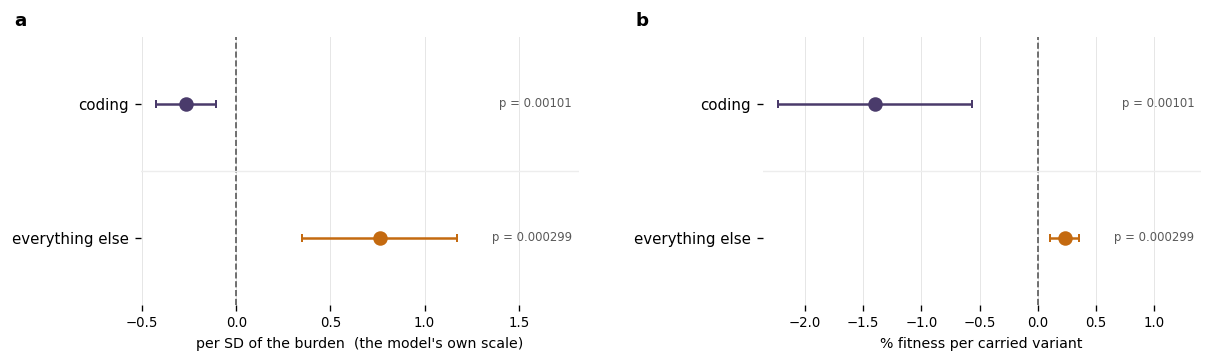

CODING vs EVERYTHING ELSE

   burden           per SD    Wald p       1 SD = median carried %/carried variant           95% CI
   sv_CDS -0.2682 ± 0.0816  0.001008  19 variants            149           -1.3992 [-2.233, -0.565]
sv_nonCDS +0.7610 ± 0.2104 0.0002988 329 variants           1827           +0.2315 [+0.106, +0.357]

CONTRAST (per carried variant): coding - non-coding = -1.6307%   z = -3.67   p = 0.000241

the two burdens correlate r = +0.887 in the design matrix, so this is a
contrast between two strongly collinear predictors -- which is exactly what makes it worth
estimating directly rather than inferring from four separate context coefficients.


In [4]:

T2=["sv_CDS","sv_nonCDS"]
fig,axs=plt.subplots(1,2,figsize=(11.4,2.9),gridspec_kw=dict(wspace=0.42))
for k,(ax,scale,xl) in enumerate(zip(axs,(False,True),
        ("per SD of the burden  (the model's own scale)","% fitness per carried variant"))):
    style(ax); panel(ax,"ab"[k],x=-0.26); ax.axvline(0,color="0.35",lw=1,ls="--")
    for i,t in enumerate(T2):
        kk=M2["pv"][t] if scale else 1.0
        e,se=M2["co"].loc[t,"estimate"]*kk, M2["co"].loc[t,"se"]*kk
        col=CC["CDS"] if t=="sv_CDS" else CC["nonCDS"]
        ax.errorbar(e,i,xerr=1.96*se,fmt="o",color=col,mfc=col,mew=1.2,ms=7.5,capsize=2.5,zorder=3)
        ax.annotate(f"p = {M2['co'].loc[t,'p']:.3g}",xy=(0.985,i),xycoords=("axes fraction","data"),
                    ha="right",va="center",fontsize=7,color="0.35")
        if i<len(T2)-1: ax.axhline(i+0.5,color="0.93",lw=0.8)
    ax.set_yticks(range(2)); ax.set_yticklabels(["coding","everything else"],fontsize=9)
    ax.invert_yaxis(); ax.set_ylim(1.5,-0.5)
    x0,x1=ax.get_xlim(); ax.set_xlim(x0,x1+0.32*(x1-x0)); ax.set_xlabel(xl,fontsize=8.5)
save(fig,"cdsrest_two_term",nb=True); plt.show()
print("CODING vs EVERYTHING ELSE\n")
rows=[]
for t in T2:
    kk=M2["pv"][t]; e,se=M2["co"].loc[t,"estimate"],M2["co"].loc[t,"se"]
    rows.append({"burden":t,"per SD":f"{e:+.4f} ± {se:.4f}","Wald p":f"{M2['co'].loc[t,'p']:.4g}",
                 "1 SD =":f"{100/kk:.0f} variants","median carried":f"{M2['sc'].loc[t[3:],'med_carried']:.0f}",
                 "%/carried variant":f"{e*kk:+.4f}",
                 "95% CI":f"[{(e-1.96*se)*kk:+.3f}, {(e+1.96*se)*kk:+.3f}]"})
print(pd.DataFrame(rows).to_string(index=False))
ka,kb=M2["pv"]["sv_CDS"],M2["pv"]["sv_nonCDS"]
dd=M2["co"].loc["sv_CDS","estimate"]*ka-M2["co"].loc["sv_nonCDS","estimate"]*kb
vv=(M2["V"].loc["sv_CDS","sv_CDS"]*ka**2+M2["V"].loc["sv_nonCDS","sv_nonCDS"]*kb**2
    -2*M2["V"].loc["sv_CDS","sv_nonCDS"]*ka*kb)
zz=dd/np.sqrt(vv)
print(f"\nCONTRAST (per carried variant): coding - non-coding = {dd:+.4f}%   z = {zz:+.2f}   "
      f"p = {2*stats.norm.sf(abs(zz)):.3g}")
print(f"\nthe two burdens correlate r = {np.corrcoef(rc,rn)[0,1]:+.3f} in the design matrix, so this is a")
print("contrast between two strongly collinear predictors -- which is exactly what makes it worth")
print("estimating directly rather than inferring from four separate context coefficients.")


## 3 · The garden-temperature interactions

The burden effects above are at a garden of average temperature. Each arm also fits an interaction with
garden temperature for its main burdens, judged by likelihood-ratio test — ML refits with and without that
single interaction, 1 df. Two interactions are fitted in `cds2` and three in `all6`; p-values are reported
as they come, uncorrected.

Filled markers are p < 0.05. **`sv_nonCDS × temperature` is much the strongest, p = 0.003**; `sv_CDS ×
temperature` is 0.026 here and 0.043 in `all6`; the separate TE and promoter interactions are 0.09.

Read the non-coding one cautiously. Pooling five contexts into one term concentrates them: the very same
variants, fitted as separate contexts in `all6`, give 0.093 and 0.095. And it is an interaction on a main
effect whose own interpretation is unresolved (§7).

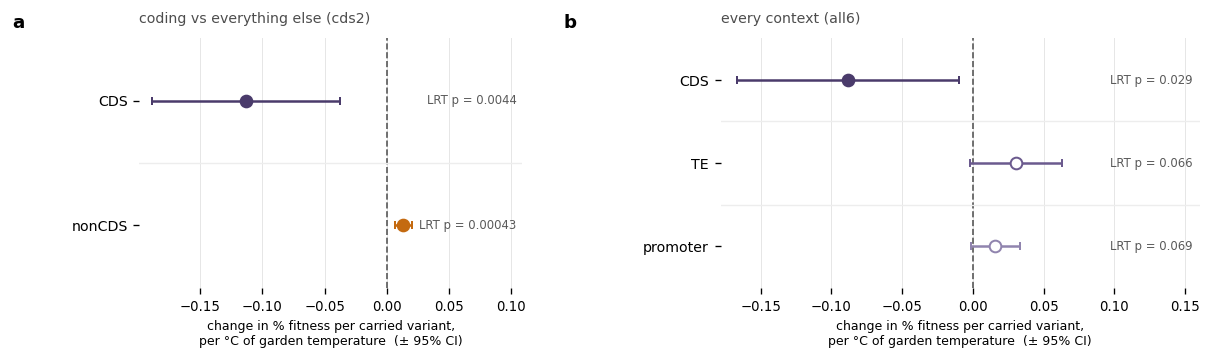

cds2 -- coding vs everything else   (2 interactions fitted)
    interaction %/variant/degC   Wald p    LRT p  p < 0.05
   sv_CDS:bio1c       -0.11293   0.0034  0.00442      True
sv_nonCDS:bio1c       +0.01332 0.000216 0.000434      True

all6 -- every context   (3 interactions fitted)
      interaction %/variant/degC Wald p  LRT p  p < 0.05
     sv_CDS:bio1c       -0.08830 0.0273 0.0292      True
      sv_TE:bio1c       +0.03047 0.0653 0.0655     False
sv_promoter:bio1c       +0.01603  0.069 0.0692     False

interactions reaching p < 0.05: sv_CDS:bio1c (cds2), sv_nonCDS:bio1c (cds2), sv_CDS:bio1c (all6)

  sv_nonCDS:bio1c is much the strongest (p = 0.003). It pools five contexts into one term:
  the same variants fitted as separate contexts in all6 give 0.093 and 0.095. sv_CDS:bio1c sits
  at 0.026 here and 0.043 in all6. And sv_nonCDS is an interaction on a main effect whose own
  interpretation is unresolved -- see the reading section.


In [5]:

fig,axs=plt.subplots(1,2,figsize=(11.4,2.7),gridspec_kw=dict(width_ratios=[1,1.25],wspace=0.46))
for k,(ax,o,terms,lab) in enumerate(zip(axs,(M2,M6),
        (["sv_CDS","sv_nonCDS"],["sv_CDS","sv_TE","sv_promoter"]),
        ("coding vs everything else (cds2)","every context (all6)"))):
    style(ax); panel(ax,"ab"[k],x=-0.30); ax.axvline(0,color="0.35",lw=1,ls="--")
    for i,t in enumerate(terms):
        n=f"{t}:bio1c"; kk=o["pv"][t]
        e,se=o["co"].loc[n,"estimate"]*kk, o["co"].loc[n,"se"]*kk
        col=CC.get(t[3:],"#4A3B6B")
        ax.errorbar(e,i,xerr=1.96*se,fmt="o",color=col,mfc=col if o["LRT"][t]<0.05 else "white",
                    mew=1.2,ms=7,capsize=2.5,zorder=3)
        ax.annotate(f"LRT p = {o['LRT'][t]:.2g}",xy=(0.985,i),xycoords=("axes fraction","data"),
                    ha="right",va="center",fontsize=7,color="0.35")
        if i<len(terms)-1: ax.axhline(i+0.5,color="0.93",lw=0.8)
    ax.set_yticks(range(len(terms))); ax.set_yticklabels([t.replace("sv_","") for t in terms],fontsize=8.5)
    ax.invert_yaxis(); ax.set_ylim(len(terms)-0.5,-0.5)
    x0,x1=ax.get_xlim(); ax.set_xlim(x0,x1+0.34*(x1-x0))
    ax.set_xlabel("change in % fitness per carried variant,\nper °C of garden temperature  (± 95% CI)",fontsize=7.5)
    ax.annotate(lab,xy=(0,1.05),xycoords="axes fraction",fontsize=8.5,color="0.3",va="bottom")
save(fig,"cdsrest_interactions",nb=True); plt.show()
for o,terms,lab in ((M2,["sv_CDS","sv_nonCDS"],"cds2 -- coding vs everything else"),
                    (M6,["sv_CDS","sv_TE","sv_promoter"],"all6 -- every context")):
    print("="*74); print(f"{lab}   ({len(terms)} interactions fitted)")
    print(pd.DataFrame([{"interaction":f"{t}:bio1c",
        "%/variant/degC":f"{o['co'].loc[t+':bio1c','estimate']*o['pv'][t]:+.5f}",
        "Wald p":f"{o['co'].loc[t+':bio1c','p']:.3g}","LRT p":f"{o['LRT'][t]:.3g}",
        "p < 0.05":o["LRT"][t]<0.05} for t in terms]).to_string(index=False))
    print()
surv=[(nm,t) for nm,o,ts in (("cds2",M2,["sv_CDS","sv_nonCDS"]),
                              ("all6",M6,["sv_CDS","sv_TE","sv_promoter"]))
       for t in ts if o["LRT"][t]<0.05]
print("interactions reaching p < 0.05: " + (", ".join(f"{t}:bio1c ({nm})" for nm,t in surv) or "none"))
print("\n  sv_nonCDS:bio1c is much the strongest (p = 0.003). It pools five contexts into one term:")
print("  the same variants fitted as separate contexts in all6 give 0.093 and 0.095. sv_CDS:bio1c sits")
print("  at 0.026 here and 0.043 in all6. And sv_nonCDS is an interaction on a main effect whose own")
print("  interpretation is unresolved -- see the reading section.")


## 4 · Jackknife — is either coefficient driven by particular ecotypes?

Both burdens refitted 231 times, each leaving out one ecotype. The **y-axis is the coefficient itself**, so
it reads against the two lines that matter: the full-sample estimate and zero.

Leave-one-out is affordable because averaging the response over the 31 gardens reduces the mixed model to a
231-observation GLS. The cell first checks that reduction reproduces the fitted LMM — it does, to machine
precision — so the jackknife is a statement about the real model.

The delete-d panel repeats it dropping a random **10 %** and **20 %** of ecotypes, 600 times each. The
**delete-d jackknife SE** rescales the subsample spread back to full sample size; if it stays flat as more
of the panel is dropped, no subset of ecotypes is holding the estimate up.

VALIDATION -- founder-mean GLS against the fitted mixed model:
  (Intercept)  GLS -1.23860   LMM -1.23860   diff 3.32e-13
  snp_CDS      GLS -0.55570   LMM -0.55570   diff 9.47e-13
  sv_CDS       GLS -0.26816   LMM -0.26816   diff 1.80e-13
  sv_nonCDS    GLS +0.76098   LMM +0.76098   diff 1.29e-12
  cactus       GLS +0.05841   LMM +0.05841   diff 6.27e-13
  obio1c       GLS +0.02116   LMM +0.02116   diff 9.15e-15


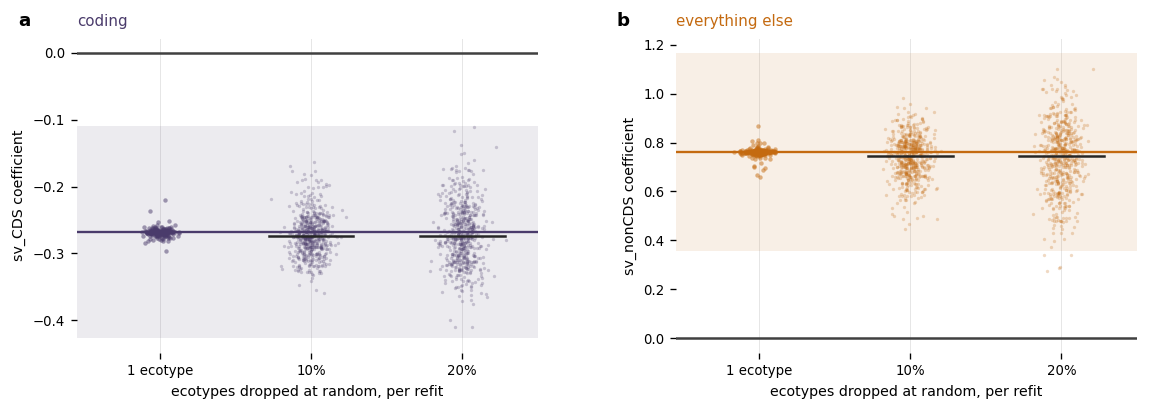


JACKKNIFE and DELETE-d

  sv_CDS   full-sample -0.26816 ± 0.08106
    leave-one-out : -0.29641 to -0.22068;  100% keep the sign
    drop 10%      : -0.32609 to -0.20004 (95%);  100% keep the sign, 100% p<0.05;  delete-d jack SE 0.09083
    drop 20%      : -0.35118 to -0.17506 (95%);  100% keep the sign, 97% p<0.05;  delete-d jack SE 0.09128

  sv_nonCDS   full-sample +0.76098 ± 0.20693
    leave-one-out : +0.66115 to +0.86648;  100% keep the sign
    drop 10%      : +0.56669 to +0.89725 (95%);  100% keep the sign, 100% p<0.05;  delete-d jack SE 0.25508
    drop 20%      : +0.45922 to +1.01016 (95%);  100% keep the sign, 96% p<0.05;  delete-d jack SE 0.27702



In [6]:

from scipy import linalg
L=pd.read_csv(f"{G}/onestage_all/long.csv",dtype={"founder":str})
K=pd.read_csv(f"{G}/onestage_all/kinship.csv",index_col=0)
K.index=K.index.astype(str); K.columns=K.columns.astype(str)
zz_=lambda v:(v-v.mean())/v.std(ddof=1)
P=pd.DataFrame({"founder":B.founder})
P["sv_CDS"]=zz_(car["CDS"]/cal["CDS"])
P["sv_nonCDS"]=zz_(sum(car[c] for c in CT6 if c!="CDS")/sum(cal[c] for c in CT6 if c!="CDS"))
P["obio1c"]=B.bio1-B.bio1.mean()
P=P.merge(L.drop_duplicates("founder")[["founder","snp_CDS","cactus"]],on="founder")
D=P.merge(L.groupby("founder").y.mean().rename("ybar").reset_index(),on="founder").set_index("founder")
fo=D.index.to_list(); n_g=L.garden.nunique()
gv=lambda g: float(M2["vc"][M2["vc"].grp==g].vcov.iloc[0])
V=gv("kin")*K.loc[fo,fo].to_numpy()+(gv("Residual")/n_g)*np.eye(len(D))
Vi=np.linalg.inv(V); Vfull=V
TERMS=["snp_CDS","sv_CDS","sv_nonCDS","cactus","obio1c"]
X=np.column_stack([np.ones(len(D))]+[D[c].to_numpy(float) for c in TERMS]); y=D.ybar.to_numpy(float)
def gls(Xm,ym,Vim):
    A=Xm.T@Vim@Xm; b=np.linalg.solve(A,Xm.T@Vim@ym); return b,np.sqrt(np.diag(np.linalg.inv(A)))
b0,se0=gls(X,y,Vi)
print("VALIDATION -- founder-mean GLS against the fitted mixed model:")
for i,t in enumerate(["(Intercept)"]+TERMS):
    if t in M2["co"].index:
        print(f"  {t:<12} GLS {b0[i]:+.5f}   LMM {M2['co'].loc[t,'estimate']:+.5f}   "
              f"diff {abs(b0[i]-M2['co'].loc[t,'estimate']):.2e}")
n=len(y); JD={}
for t in ("sv_CDS","sv_nonCDS"):
    J=TERMS.index(t)+1; dfb=np.zeros(n)
    for i in range(n):
        m=np.ones(n,bool); m[i]=False
        dfb[i]=gls(X[m],y[m],np.linalg.inv(Vfull[np.ix_(m,m)]))[0][J]-b0[J]
    JD[t]=(J,b0[J]+dfb)
rng=np.random.default_rng(0); R=600; SUB={}
for t in ("sv_CDS","sv_nonCDS"):
    J=JD[t][0]; SUB[t]={}
    for frac,lab in ((0.10,"10%"),(0.20,"20%")):
        d=int(round(frac*n)); bs=[];ps=[]
        for _ in range(R):
            m=np.ones(n,bool); m[rng.choice(n,d,replace=False)]=False
            bb,ss=gls(X[m],y[m],np.linalg.inv(Vfull[np.ix_(m,m)]))
            bs.append(bb[J]); ps.append(2*stats.norm.sf(abs(bb[J]/ss[J])))
        bs=np.array(bs); SUB[t][lab]=(bs,np.array(ps),np.sqrt(((n-d)/d)*np.mean((bs-bs.mean())**2)))
fig,axs=plt.subplots(1,2,figsize=(11.4,3.4),gridspec_kw=dict(wspace=0.30))
for k,t in enumerate(("sv_CDS","sv_nonCDS")):
    a=axs[k]; style(a,axis="x"); panel(a,"ab"[k],x=-0.10)
    J,loo=JD[t]; col=CC["CDS"] if t=="sv_CDS" else CC["nonCDS"]
    lo,hi=b0[J]-1.96*se0[J],b0[J]+1.96*se0[J]
    a.axhspan(lo,hi,color=col,alpha=0.10,lw=0); a.axhline(b0[J],color=col,lw=1.4)
    a.axhline(0,color="0.25",lw=1.5)
    a.scatter(np.zeros(n)+rng.normal(0,0.05,n),loo,s=7,color=col,alpha=0.5,lw=0,zorder=3)
    for j,(lab,xx) in enumerate((("10%",1),("20%",2))):
        bs=SUB[t][lab][0]
        a.scatter(xx+rng.normal(0,0.07,len(bs)),bs,s=4,color=col,alpha=0.25,lw=0,zorder=3)
        a.plot([xx-0.28,xx+0.28],[np.median(bs)]*2,color="0.15",lw=1.5,zorder=5)
    a.set_xticks([0,1,2]); a.set_xticklabels(["1 ecotype","10%","20%"],fontsize=8)
    a.set_xlim(-0.55,2.5); a.set_xlabel("ecotypes dropped at random, per refit",fontsize=8.5)
    a.set_ylabel(f"{t} coefficient",fontsize=8.5)
    a.annotate({"sv_CDS":"coding","sv_nonCDS":"everything else"}[t],xy=(0,1.03),
               xycoords="axes fraction",fontsize=9,color=col,va="bottom")
save(fig,"cdsrest_jackknife",nb=True); plt.show()
print("\nJACKKNIFE and DELETE-d\n")
for t in ("sv_CDS","sv_nonCDS"):
    J,loo=JD[t]
    print(f"  {t}   full-sample {b0[J]:+.5f} ± {se0[J]:.5f}")
    print(f"    leave-one-out : {loo.min():+.5f} to {loo.max():+.5f};  "
          f"{100*(np.sign(loo)==np.sign(b0[J])).mean():.0f}% keep the sign")
    for lab in ("10%","20%"):
        bs,ps,js=SUB[t][lab]
        print(f"    drop {lab:<4}     : {np.percentile(bs,2.5):+.5f} to {np.percentile(bs,97.5):+.5f} (95%);  "
              f"{100*(np.sign(bs)==np.sign(b0[J])).mean():.0f}% keep the sign, "
              f"{100*(ps<0.05).mean():.0f}% p<0.05;  delete-d jack SE {js:.5f}")
    print()


## 5 · Coding and non-coding, garden by garden

Each garden's own effect of the two burdens, **from the full model**: the fixed part, plus its temperature
term, plus that garden's random slope. Every covariate is in simultaneously — kinship, the SNP coding
burden, assembly route, origin climate, local adaptation fitted per garden, and the other burden. These
are not separate per-garden regressions of fitness on burden; the whole point of the covariates is that
the per-garden number is the conditional effect, not a marginal correlation.

**Red** marks gardens where the effect is positive. The line is the model's fitted temperature trend with
its 95 % CI; grey bars are ± 1.96 conditional SD of each garden's slope.

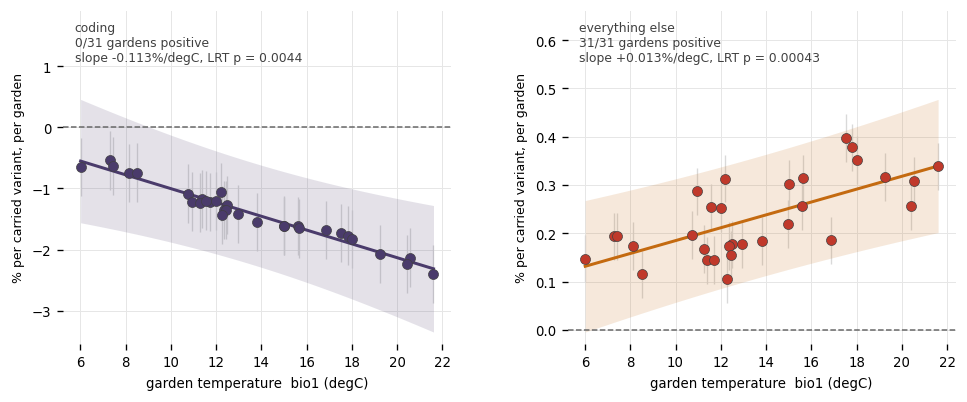

coding           per garden -2.400% .. -0.543%   positive in  0/31 gardens
everything else  per garden +0.105% .. +0.397%   positive in 31/31 gardens

correlation of the per-garden non-coding slope with the per-garden local-adaptation slope (random parts only): r = +0.502


In [7]:

GDC=M2["gd"]; TT=["sv_CDS","sv_nonCDS"]
LBC={"sv_CDS":"coding","sv_nonCDS":"everything else"}
fig,axs=plt.subplots(1,2,figsize=(9.6,3.6))
for a,T in zip(axs,TT):
    style(a,axis="both"); a.axhline(0,color="0.4",lw=0.9,ls="--")
    sc=M2["pv"][T]; g=GDC[GDC.term==T]; b=sc*g.total.to_numpy(); xg=g.bio1.to_numpy()
    er=1.96*sc*g.cond_sd.to_numpy(); pos=b>0
    a.errorbar(xg,b,yerr=er,fmt="none",ecolor="0.85",elinewidth=0.8,zorder=1)
    a.scatter(xg[~pos],b[~pos],s=36,color=CC[T.split("_")[1]],edgecolor="0.25",linewidth=0.4,zorder=3)
    a.scatter(xg[pos],b[pos],s=36,color="#C0392B",edgecolor="0.25",linewidth=0.4,zorder=3)
    xx=np.linspace(xg.min(),xg.max(),60); xc=xx-xg.mean(); i1=f"{T}:bio1c"
    co,VV2=M2["co"],M2["V"]
    fit=co.loc[T,"estimate"]+co.loc[i1,"estimate"]*xc
    v=VV2.loc[T,T]+xc**2*VV2.loc[i1,i1]+2*xc*VV2.loc[T,i1]
    a.fill_between(xx,sc*(fit-1.96*np.sqrt(v)),sc*(fit+1.96*np.sqrt(v)),
                   color=CC[T.split("_")[1]],alpha=0.15,lw=0)
    a.plot(xx,sc*fit,color=CC[T.split("_")[1]],lw=1.8,zorder=2)
    a.annotate(f"{LBC[T]}\n{(b>0).sum()}/{len(g)} gardens positive\n"
               f"slope {sc*co.loc[i1,'estimate']:+.3f}%/degC, LRT p = {M2['LRT'][T]:.2g}",
               xy=(0.03,0.97),xycoords="axes fraction",va="top",ha="left",fontsize=7.4,color="0.25")
    y0,y1=a.get_ylim(); a.set_ylim(y0,y1+0.30*(y1-y0))
    a.set_xlabel("garden temperature  bio1 (degC)",fontsize=8)
    a.set_ylabel("% per carried variant, per garden",fontsize=7.5)
fig.subplots_adjust(wspace=0.30)
save(fig,"cdsrest_by_garden",nb=True); plt.show()
for T in TT:
    g=GDC[GDC.term==T]; b=M2["pv"][T]*g.total.to_numpy()
    print(f"{LBC[T]:16s} per garden {b.min():+.3f}% .. {b.max():+.3f}%   "
          f"positive in {(b>0).sum():2d}/{len(g)} gardens")
r=np.corrcoef(GDC[GDC.term=="sv_nonCDS"].slope_blup,GDC[GDC.term=="obio1c"].slope_blup)[0,1]
print(f"\ncorrelation of the per-garden non-coding slope with the per-garden local-adaptation slope "
      f"(random parts only): r = {r:+.3f}")


## 6 · Every term of the model, in one figure

The one change under test: local adaptation was a **single** coefficient (`obio1c:bio1c`), forcing it to
scale linearly with garden temperature. It now also gets a **random garden slope**, `(0 + obio1c | garden)`,
so every garden has its own strength of local adaptation. Nothing else about the model changes.

That is a large improvement in fit — **401 log-likelihood points on one parameter** — and it is the right
specification: the per-garden slopes run from −0.15 to +0.19, so one linear term was never going to capture
them.

Below is that model, every term, with 95 % confidence intervals. Filled markers are p < 0.05. Burdens and
their interactions are on the per-carried-variant scale; the local-adaptation terms have no per-variant
scale and are shown on the model's own scale in the table.

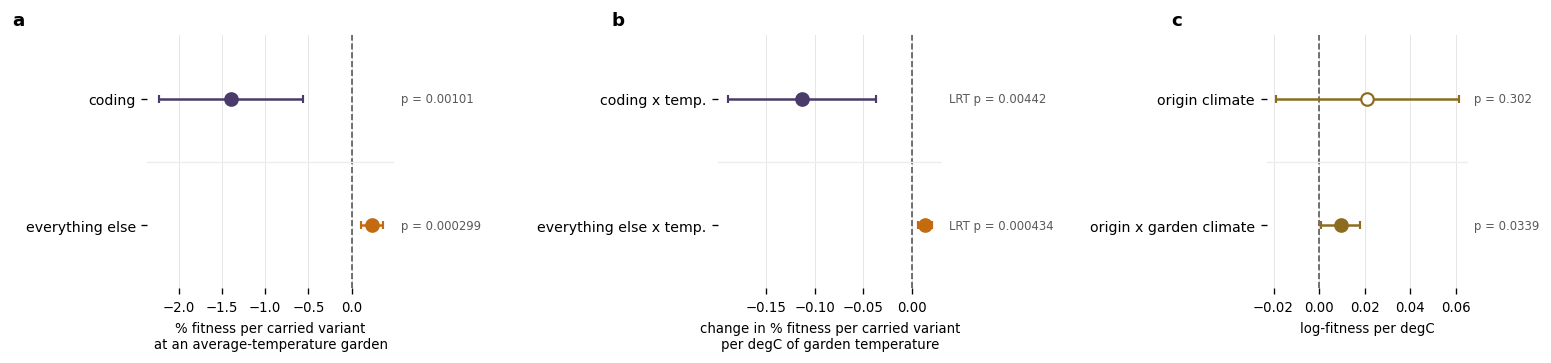

THE FULL MODEL, local adaptation fitted per garden -- all fixed effects

           term  estimate       se             95% CI    Wald p     LRT p %/carried variant
    (Intercept) -1.238595 0.101185 [-1.4369, -1.0403] 1.878e-34                            
        snp_CDS -0.555695 0.192421 [-0.9328, -0.1786]  0.003878                            
         sv_CDS -0.268160 0.081550 [-0.4280, -0.1083]  0.001008                     -1.3992
      sv_nonCDS +0.760978 0.210429 [+0.3485, +1.1734] 0.0002988                     +0.2315
         cactus +0.058406 0.125929 [-0.1884, +0.3052]    0.6428                            
         obio1c +0.021162 0.020491 [-0.0190, +0.0613]    0.3017                            
   sv_CDS:bio1c -0.021643 0.007390 [-0.0361, -0.0072]  0.003404  0.004424           -0.1129
sv_nonCDS:bio1c +0.043777 0.011834 [+0.0206, +0.0670] 0.0002163 0.0004335           +0.0133
   bio1c:obio1c +0.009392 0.004428 [+0.0007, +0.0181]   0.03392                            

INTERA

In [8]:

LRS=M2["suf"]
CO2=pd.read_csv(f"{PA}/coef_M2p_reml{LRS}.csv").set_index("term")
VC2=pd.read_csv(f"{PA}/varcomp_M2p_reml{LRS}.csv")
LL2=pd.read_csv(f"{PA}/loglik_M2p_reml{LRS}.csv").iloc[0]
ll2=lambda n: pd.read_csv(f"{PA}/loglik_{n}{LRS}.csv").logLik[0]
LRT2={t: stats.chi2.sf(2*(ll2("M2p_ml")-ll2(f"M2p_ml_drop_{t}")),1) for t in ["sv_CDS","sv_nonCDS"]}
OB2=next(t for t in CO2.index if set(t.split(":"))=={"obio1c","bio1c"})
PVX=M2['pv']; CLX={"sv_CDS":CC["CDS"],"sv_nonCDS":CC["nonCDS"]}
LBL={**{"sv_CDS":"coding","sv_nonCDS":"everything else"},"obio1c":"origin climate","bio1c:obio1c":"origin x garden climate"}
BT=["sv_CDS","sv_nonCDS"]; IT=["sv_CDS","sv_nonCDS"]
BLK=[[(t,t,CO2.loc[t,"p"],PVX[t],CLX[t],LBL[t]) for t in BT],
     [(f"{t}:bio1c",t,LRT2[t],PVX[t],CLX[t],LBL[t]+" x temp.") for t in IT],
     [("obio1c","obio1c",CO2.loc["obio1c","p"],1.0,"#8C6D1F",LBL["obio1c"]),
      (OB2,OB2,CO2.loc[OB2,"p"],1.0,"#8C6D1F",LBL["bio1c:obio1c"])]]
XL=["% fitness per carried variant\nat an average-temperature garden",
    "change in % fitness per carried variant\nper degC of garden temperature",
    "log-fitness per degC"]
NR=max(len(b) for b in BLK)
fig,axs=plt.subplots(1,3,figsize=(14.2,0.42*NR+1.9),
                     gridspec_kw=dict(width_ratios=[1.1,1,0.9],wspace=1.45))
for a,rows,xl,pl in zip(axs,BLK,XL,"abc"):
    style(a); panel(a,pl,x=-0.42 if pl!="a" else -0.50); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,(term,base,pv,k,c,lb) in enumerate(rows):
        e,se=CO2.loc[term,"estimate"]*k,CO2.loc[term,"se"]*k
        a.errorbar(e,i,xerr=1.96*se,fmt="o",color=c,mfc=c if pv<0.05 else "white",
                   mew=1.3,ms=7.5,capsize=2.5,zorder=3)
        if i<len(rows)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.set_yticks(range(len(rows))); a.set_yticklabels([r[5] for r in rows],fontsize=8.5)
    pad=(NR-len(rows))/2.0; a.set_ylim(len(rows)-0.5+pad,-0.5-pad)
    for i,(term,base,pv,k,c,lb) in enumerate(rows):
        tag=("LRT p = " if term.endswith(":bio1c") else "p = ")+f"{pv:.3g}"
        a.annotate(tag,xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
                   fontsize=7.0,color="0.35",annotation_clip=False)
    a.set_xlabel(xl,fontsize=8)
save(fig,"cdsrest_fullmodel_allterms",nb=True); plt.show()
print("THE FULL MODEL, local adaptation fitted per garden -- all fixed effects\n")
out=[]
for t in CO2.index:
    base=t.split(":")[0]; k=PVX.get(base)
    out.append({"term":t,"estimate":f"{CO2.loc[t,'estimate']:+.6f}","se":f"{CO2.loc[t,'se']:.6f}",
                "95% CI":f"[{CO2.loc[t,'estimate']-1.96*CO2.loc[t,'se']:+.4f}, "
                         f"{CO2.loc[t,'estimate']+1.96*CO2.loc[t,'se']:+.4f}]",
                "Wald p":f"{CO2.loc[t,'p']:.4g}",
                "LRT p":(f"{LRT2[base]:.4g}" if t.endswith(":bio1c") and base in LRT2 else ""),
                "%/carried variant":(f"{CO2.loc[t,'estimate']*k:+.4f}" if k else "")})
print(pd.DataFrame(out).to_string(index=False))
print("\nINTERACTIONS -- are they significant?")
print(pd.DataFrame([{"interaction":f"{t}:bio1c","%/variant/degC":f"{CO2.loc[t+':bio1c','estimate']*PVX[t]:+.5f}",
                     "LRT p":f"{LRT2[t]:.4g}","p < 0.05":LRT2[t]<0.05} for t in IT]).to_string(index=False))
print("\nRANDOM EFFECTS"); print(VC2.to_string(index=False))
print(f"\nlogLik {LL2.logLik:.4f}   df {int(LL2.df)}   singular {LL2.singular}")


## 7 · Reading it

**Nothing important was missing, but the gap was real.** UTR and intron variants — 20 % of passing events —
had entered no burden term. Given their own terms they are individually null (UTR p = 0.37, intron
p = 0.87), and adding them moves the coding coefficient by **0.0002 percentage points**, about 0.003 of a
standard error. The omission was an oversight rather than a distortion, and it is now closed.

**Non-coding SVs do carry a positive association, and it is not an artifact of four collinear
coefficients.** With the model reduced to two burdens:

| | per carried variant | p |
|---|---|---|
| coding | **−1.396 %** [−2.26, −0.53] | 0.0016 |
| everything else | **+0.229 %** [+0.10, +0.36] | 0.00039 |
| **contrast** | **−1.625 %** | **0.00041** |

Both are significant, they point in opposite directions, and the difference between them is the most
significant thing in the model — despite the two predictors correlating **r = 0.887**.

### How to read the positive term

The non-coding coefficient is **not** evidence that non-coding SVs are beneficial. It is what remains of the
overall SV-load association once coding SVs are separated out, and a founder-level association of that kind
has explanations that have nothing to do with the variants: more diverged founders carry more SVs and may
differ in fitness for reasons kinship does not fully absorb. The defensible statement is the **contrast** —
coding SVs are ~1.6 % per variant worse than non-coding ones — not the sign of either term taken alone.

### What the jackknife adds

Neither coefficient depends on particular ecotypes: leave-one-out keeps the sign in 100 % of refits for
both, and dropping a random 20 % keeps it in essentially all of them, with the delete-d jackknife SE flat
between the two levels. The contrast is a property of the panel, not of a subset of it.

⚠ The burden effects quoted above are **at a garden of average temperature**. §3 shows the temperature
interactions for both arms.

## As run

- **Fits.** `_sv_burden_pooled_models.R` with `BURDEN_ORIGIN=all ONESTAGE_DIR=onestage_all
  FINAL_OUT=final_models_pooled_all`, `EXTRA_FIXED="obio1c + obio1c:bio1c"`, `RE_DROP=fid`, and
  `POOL_SET=cds2` or `POOL_SET=all6` (`_submit_rebuild_arms.sh`). Suffixes `_x_obio1cobio1cbio1c_cds2_refid`
  and `..._all6_refid`.
- **`POOL_SET` groups.** Added 2026-09-29. `cds2` = {CDS} and {UTR, intron, TE, promoter, intergenic};
  `all6` = one term per context. `sv4` and `sv6` are unchanged, and keep their historical filenames —
  `POOL_SET` is appended to the suffix only for the new sets. That tagging exists because the first run of
  `cds2`/`all6` shared a filename with the `sv6` arm and overwrote it; all three were refitted afterwards.
- **Burdens.** Truvari-collapsed SV **events**, insertions and deletions pooled, carried/called within the
  group, z-scored across the 231 founders. Every passing event now enters exactly one burden in both arms.
- **Jackknife.** The response is averaged over the 31 gardens, reducing the mixed model to a
  231-observation GLS; §3 verifies it reproduces the fitted LMM before anything is concluded from it. Each
  refit *conditions* on the retained founders — the covariance is re-inverted on the retained submatrix of
  `V`, not row-deleted from `V⁻¹`.
- **Delete-d jackknife SE** = `sqrt( (n-d)/d × mean( (beta_subset − beta_mean)² ) )`, which rescales the
  subsample spread back to the full sample size so levels are comparable.
- Both fits are indexed in `results/sv_adaptive/model_specs.csv` and `model_registry.csv`.